# Ground station census

Given a rectangular bounding box, this notebook queries the OpenAQ database for PM2.5 stations
in that region, narrows them down to ones still actively reporting, and then -- separately --
determines which of those have a long enough, gap-free-at-the-edges reporting history to
support various candidate study periods.

Two independent checks:

1. **Recency** (is the sensor reporting *right now*): pull the network-wide `latest` feed for
   PM2.5 once (paginated), join it against the candidate stations on sensor ID, and keep
   stations whose last reading is within `MAX_AGE_DAYS` (`flag_active_stations`). This is a
   cheap, bulk pre-filter used only to bound the next, expensive step -- it says nothing about
   whether a sensor's history covers any particular study window.
2. **Period coverage** (does the sensor's reporting period cover a candidate study window):
   only for sensors that passed the recency check, pull each one's true `datetime_first`/
   `datetime_last` (`pull_sensor_period`, one paced API call per sensor, cached to disk) and
   check coverage against a window with `sensors_covering_period`/`count_sensors_covering_period`.
   This has no "now" dependency at all -- it's pure per-sensor history math, safe to sweep
   across many candidate windows for free once the pull is done. Note this only rules out
   sensors that started too late or stopped too early relative to the window edges; it can't
   catch gaps *within* the window (e.g. six months offline in the middle) -- that needs to be
   checked against the actual pulled measurements in the next notebook.

These two are kept deliberately separate (see `fetch_openaq.py`'s module docstring) -- an
earlier version bundled them into one `is_active` flag, which meant a period-coverage result
silently also depended on wall-clock time at call time.

This is a quick sanity check on the candidate region *before* building the rest of the pipeline. If the region
doesn't have enough well-distributed, sufficiently-long-reporting active stations, the fallback regions are
Sub-Saharan Africa's OpenAQ-reporting countries or a Latin America cluster (Mexico, Colombia, Peru, Brazil).

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import dotenv
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from openaq import OpenAQ

import monitoring_deserts.data.fetch_openaq as census

## Configuration

Candidate region: South Asia (India, Pakistan, Bangladesh, Nepal, Sri Lanka) plus Afghanistan,
per the plan's Section 3 recommendation. Study period: subject to change according to the finding
of the census. Ideally the most recent two years.

In [3]:
# Bounding box: (min lon, min lat, max lon, max lat) -- South Asia + Afghanistan
BOUNDING_BOX = (60.424805, 5.353521, 93.383789, 38.272689)

# Half-open analysis period
PERIOD = DAY_START, DAY_END = ("2024-01-01", "2026-07-01")

# A station's PM2.5 sensor must have reported within this many days of today
# to be considered active.
MAX_AGE_DAYS = 100

# Rough viability bar: below this, fall back to
# one of the alternate regions rather than building the rest of
# the pipeline on a too-sparse network.
MIN_ACTIVE_STATIONS = 40

OUTPUT_DIR = Path("../data/raw/station_census")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dotenv.load_dotenv()
client = OpenAQ()

## Step 1 — PM2.5 parameter ID

Don't hardcode this; OpenAQ assigns it, so confirm it directly.

In [4]:
pm25_id = census.get_pollutant_id(client, poll_name="PM25")
print(f"PM2.5 parameter ID: {pm25_id}")

PM2.5 parameter ID: 2


## Step 2 — Candidate stations in the bounding box

All stations in `BOUNDING_BOX` that have at least one PM2.5 sensor, regardless of whether
that sensor is still active.

In [5]:
stations_df, stations_list = census.pull_stations(client, BOUNDING_BOX, pollutant_id=pm25_id)
print(f"Candidate PM2.5 stations in the bounding box: {len(stations_df)}")
stations_df[["id", "name", "country.code", "country.name", "coordinates.latitude", "coordinates.longitude"]].head()

Candidate PM2.5 stations in the bounding box: 1352


,id,name,country.code,country.name,coordinates.latitude,coordinates.longitude
0,12,SPARTAN - IIT Kanpur,IN,India,26.519000,80.233000
1,13,"Delhi Technological University, Delhi - CPCB",IN,India,28.744000,77.120000
2,15,IGI Airport,IN,India,28.560000,77.094000
3,16,Civil Lines,IN,India,28.678700,77.226200
4,17,"R K Puram, Delhi - DPCC",IN,India,28.563262,77.186937


## Step 3 — Bulk recency check

Pull the network-wide `latest` feed for PM2.5 once (paginated) and join it against the
candidate stations on sensor ID, instead of calling `sensors.get()` once per candidate
station — the latter is what made the original version of this notebook time out after a few
hundred sequential requests.

`is_active` here reflects recency only (`MAX_AGE_DAYS`). Period coverage is a separate check,
done in Step 3a/3b below only for the sensors that pass this cheap one.

In [6]:
latest_df = census.get_latest_by_parameter(client, pm25_id)
print(f"Sensors with a recent PM2.5 reading, network-wide: {len(latest_df)}")
latest_df.head()

Sensors with a recent PM2.5 reading, network-wide: 20955


,sensor_id,location_id,latitude,longitude,value,datetime_utc,datetime_local
0,8539597,2622686,35.218150,128.574250,10.0,2026-09-17T11:00:00Z,2026-09-17T20:00:00+09:00
1,23735,8152,54.883614,23.835835,-1.0,2026-09-17T10:00:00Z,2026-09-17T13:00:00+03:00
2,238048,43487,40.146500,117.070900,16.0,2021-08-09T11:00:00Z,2021-08-09T19:00:00+08:00
3,7320157,1772963,37.645530,-118.966760,9.0,2025-08-09T14:00:00Z,2025-08-09T07:00:00-07:00
4,6236505,1066093,38.592460,-82.806770,10.7,2026-09-17T11:00:00Z,2026-09-17T07:00:00-04:00


In [7]:
stations_df = census.flag_active_stations(
    stations_df,
    stations_list,
    pm25_id,
    latest_df,
    max_age_days=MAX_AGE_DAYS,
)

n_candidate = len(stations_df)
n_recent = int(stations_df["is_active"].sum())

print(f"Candidate stations: {n_candidate}")
print(f"Reported within {MAX_AGE_DAYS} days (recency only): {n_recent}")

Candidate stations: 1352
Reported within 100 days (recency only): 893


## Step 3a — Per-sensor reporting period

`station.sensors` entries only carry `id`/`name`/`parameter` — a sensor's true
`datetime_first`/`datetime_last` needs its own `GET /sensors/{id}` call, and OpenAQ has no
bulk endpoint for it. `pull_sensor_period` fetches both for a list of sensor IDs, paced at 1
request/s.

Only sensors that already passed the recency check above are pulled. Each sensor is cached to
`sensor_period.csv` in `OUTPUT_DIR` immediately as it's fetched (via `pull_sensor_period`'s
`on_sensor_done` callback), not just at the end -- so if the pull dies partway through (e.g. a
transient OpenAQ `ServerError`, which has happened with ~900 sequential requests), everything
fetched up to that point is already saved. Re-running this cell resumes from there instead of
starting over: it only pulls sensors still missing from the cache.

`sensor_period_active`, built at the end, is the per-sensor period table restricted to this
run's active-by-recency sensors -- the input every period-coverage check below
(`sensors_covering_period`/`count_sensors_covering_period`) uses. It's pure API-independent
pandas work from here on, so it's fine to reuse across every later cell.

In [8]:
SENSOR_PERIOD_CACHE = OUTPUT_DIR / "sensor_period.csv"

if SENSOR_PERIOD_CACHE.exists():
    period_cache = pd.read_csv(SENSOR_PERIOD_CACHE, index_col="sensor_id")
else:
    period_cache = pd.DataFrame(
        columns=["datetime_first", "datetime_last"]
    ).rename_axis("sensor_id")

active_sensor_ids = (
    stations_df.loc[stations_df["is_active"], "pollutant_sensor_id"].dropna().astype(int)
)
sensor_ids_to_pull = sorted(set(active_sensor_ids) - set(period_cache.index))


def _cache_sensor_period(sensor_id, row):
    # Appends immediately, so a mid-pull failure (e.g. a transient OpenAQ
    # ServerError) doesn't lose sensors already fetched in this run.
    header = not SENSOR_PERIOD_CACHE.exists() or SENSOR_PERIOD_CACHE.stat().st_size == 0
    pd.DataFrame([row], index=pd.Index([sensor_id], name="sensor_id")).to_csv(
        SENSOR_PERIOD_CACHE, mode="a", header=header, index_label="sensor_id"
    )


if sensor_ids_to_pull:
    print(f"Pulling reporting period for {len(sensor_ids_to_pull)} sensors not in cache...")
    try:
        census.pull_sensor_period(
            client, sensor_ids_to_pull, on_sensor_done=_cache_sensor_period
        )
    except RuntimeError as exc:
        period_cache = pd.read_csv(SENSOR_PERIOD_CACHE, index_col="sensor_id")
        n_done = len(set(sensor_ids_to_pull) & set(period_cache.index))
        print(
            f"Pull failed after caching {n_done} of {len(sensor_ids_to_pull)} "
            f"sensors ({exc}). Already-pulled sensors are saved to "
            f"{SENSOR_PERIOD_CACHE} -- just re-run this cell to resume."
        )
        raise
    period_cache = pd.read_csv(SENSOR_PERIOD_CACHE, index_col="sensor_id")
else:
    print("All required sensor periods already cached -- skipping the pull.")

sensor_period_active = period_cache.loc[period_cache.index.isin(active_sensor_ids)]

All required sensor periods already cached -- skipping the pull.


## Step 3b — Period coverage for the placeholder window

Sanity-check period coverage for the placeholder `DAY_START`–`DAY_END` window before sweeping
across many candidates in Step 3c. Uses `count_sensors_covering_period` on
`sensor_period_active` -- pure pandas over already-cached data, no API calls, no "now"
dependency, safe to re-run.

In [9]:
n_active_sensors = census.count_sensors_covering_period(
    sensor_period_active, date_end=DAY_END, date_start=DAY_START
)

print(f"Sensors covering {DAY_START} to {DAY_END} (placeholder period): {n_active_sensors}")

Sensors covering 2024-01-01 to 2026-07-01 (placeholder period): 4


## Step 3c — Coverage-length sweep

`DAY_START` above picks one specific required-history length (the full `DAY_START`–`DAY_END`
window) and reports a single count for it. That number alone doesn't say much about the
*shape* of the trade-off -- whether relaxing the required history from, say, 24 months to 12
recovers a handful of sensors or triples the count. It also doesn't say anything about the
downstream data *volume* a given choice would provide.

Rather than guess at a window length, sweep the start date across the whole period and see how
both respond: `n_active_sensors` (`count_sensors_covering_period` on `sensor_period_active`)
and, in the best case where every one of those sensors contributes a usable data point for
every month of the window, `n_active_sensors * required_months` total data points for the
downstream ML step. This makes no API calls -- pure local pandas work over the already-cached
`sensor_period_active` -- so it's cheap to sweep and free to re-run.

In [10]:
day_end_period = pd.Period(DAY_END, freq="M")
candidate_starts = pd.period_range(DAY_START, DAY_END, freq="M")

sweep_rows = []
for start_period in candidate_starts:
    date_from = start_period.start_time.strftime("%Y-%m-%d")
    required_months = (day_end_period - start_period).n

    n_active_sensors = census.count_sensors_covering_period(
        sensor_period_active, date_end=DAY_END, date_start=date_from
    )
    sweep_rows.append(
        {
            "date_from": date_from,
            "required_months": required_months,
            "n_active_sensors": n_active_sensors,
            "n_datapoints_best_case": n_active_sensors * required_months,
        }
    )

coverage_curve = pd.DataFrame(sweep_rows).sort_values("required_months")
#coverage_curve

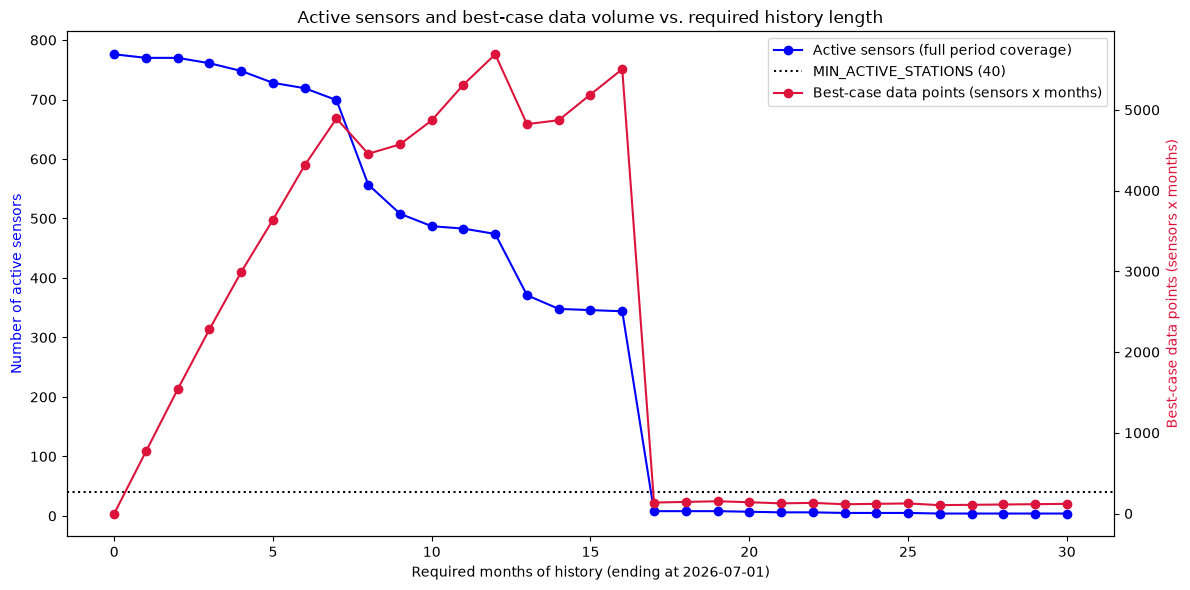

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    coverage_curve["required_months"],
    coverage_curve["n_active_sensors"],
    marker="o",
    label="Active sensors (full period coverage)",
    color="blue"
)

ax2 = ax.twinx()
ax2.plot(
    coverage_curve["required_months"],
    coverage_curve["n_datapoints_best_case"],
    marker="o",
    color="crimson",
    label="Best-case data points (sensors x months)",
)
ax2.set_ylabel("Best-case data points (sensors x months)", color="crimson")

ax.axhline(
    MIN_ACTIVE_STATIONS,
    color="black",
    linestyle=":",
    label=f"MIN_ACTIVE_STATIONS ({MIN_ACTIVE_STATIONS})",
)
ax.set_xlabel(f"Required months of history (ending at {DAY_END})")
ax.set_ylabel("Number of active sensors", color="blue")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="best")

ax.set_title("Active sensors and best-case data volume vs. required history length")
plt.tight_layout()
plt.show()

In [14]:
coverage_curve.to_csv(OUTPUT_DIR / "coverage_curve.csv", index=False)
print(f"Saved coverage curve to {OUTPUT_DIR / 'coverage_curve.csv'}")

Saved coverage curve to ../data/raw/station_census/coverage_curve.csv


## Step 4 - Determine best study period
Check the best three candidates, and manually determine which one to choose taking into account both the number 
of months and the datapoints in the best case.

In [15]:
coverage_curve.sort_values(by="n_datapoints_best_case", ascending=False).iloc[:3]

,date_from,required_months,n_active_sensors,n_datapoints_best_case
18,2025-07-01,12,474,5688
14,2025-03-01,16,344,5504
19,2025-08-01,11,483,5313


## Step 5 — Freeze the study scope and save outputs

Persist the bounding box, period, and station tables so later phases  build
on this exact decision rather than re-deriving it.


In [18]:
BEST_START = "2025-03-01"   # Manually chosen from Step 4's top-3 by best-case data volume

# Sensor-level, period-only coverage check (same logic used to build coverage_curve's
# n_datapoints_best_case in Step 3c) -- not flag_active_stations, which only ever answered a
# recency question and has no notion of BEST_START at all.
covering_sensors = census.sensors_covering_period(
    sensor_period_active, date_end=DAY_END, date_start=BEST_START
)
is_best_period_active = stations_df["pollutant_sensor_id"].isin(covering_sensors.index)
n_active = int(is_best_period_active.sum())

scope = {
    "bounding_box": {
        "min_lon": BOUNDING_BOX[0],
        "min_lat": BOUNDING_BOX[1],
        "max_lon": BOUNDING_BOX[2],
        "max_lat": BOUNDING_BOX[3],
    },
    "period": {"start": BEST_START, "end": DAY_END},
    "pm25_parameter_id": pm25_id,
    "max_age_days": MAX_AGE_DAYS,
    "n_candidate_stations": n_candidate,
    "n_recent_stations": n_recent,
    "n_active_stations": n_active,
}

with open("../configs/census_scope.yaml", "w") as f:
    yaml.safe_dump(scope, f, sort_keys=False)

stations_df.to_csv(OUTPUT_DIR / "stations_candidate.csv", index=False)
stations_df[is_best_period_active].to_csv(OUTPUT_DIR / "stations_active.csv", index=False)

# Sensor IDs of the final active stations, for pull_measurements in the next notebook to
# consume directly without re-deriving the census.
active_sensors = stations_df.loc[
    is_best_period_active,
    ["pollutant_sensor_id", "id", "name", "country.name"],
].rename(
    columns={
        "pollutant_sensor_id": "sensor_id",
        "id": "station_id",
        "name": "station_name",
        "country.name": "country",
    }
)
ACTIVE_SENSORS_PATH = OUTPUT_DIR / "active_sensors.csv"
ACTIVE_SENSORS_PATH.parent.mkdir(parents=True, exist_ok=True)
active_sensors.to_csv(ACTIVE_SENSORS_PATH, index=False)
print(f"Saved {len(active_sensors)} active sensor IDs to {ACTIVE_SENSORS_PATH}")

print(f"Saved outputs to {OUTPUT_DIR.resolve()}:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name}")

client.close()

Saved 344 active sensor IDs to ../data/raw/station_census/active_sensors.csv
Saved outputs to /home/tom/datascience/projects/monitoring_deserts/data/raw/station_census:
  .ipynb_checkpoints
  active_sensors.csv
  census_scope.yaml
  coverage_curve.csv
  sensor_period.csv
  stations_active.csv
  stations_candidate.csv


End of notebook `01_station_census.ipynb`.
___
Continue on `02_ground_truth_extraction.ipynb`.